# Food101 pHash: detect near-duplicates **within the same group**

This notebook computes perceptual hashes for the **original, untransformed** Food101 train and test images and compares images only when they belong to the selected group. It does **not** search all images and then merely filter the plots.

**Default:** `GROUP_BY = "class"` compares images with the **same Food101 class label**, including train-train, test-test and train-test pairs *if their classes agree*.

If by *group* you mean a dataset split, set `GROUP_BY = "split"` to check train-train and test-test only (no train-test comparison). To require both conditions, set `GROUP_BY = "class_and_split"`.

A low pHash Hamming distance identifies a **candidate** near-duplicate, not a confirmed duplicate; inspect the images before removing any.

Dependencies: `torchvision`, `ImageHash`, `tqdm`, and `matplotlib`. Install the missing ones with `pip install ImageHash tqdm`.

In [ ]:
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torchvision import datasets
import csv

# Settings
DATA_ROOT = "../data/asm2"
OUTPUT_CSV = DATA_ROOT / "food101_near_duplicates_same_group.csv"
OUTPUT_CSV_LEAKAGE = DATA_ROOT / "food101_data_leakage_pairs.csv"
HASH_SIZE = 8               # 8 x 8 -> 64-bit pHash
HAMMING_THRESHOLD = 10       # Candidate pairs with distance <= THRESHOLD
GROUP_BY = "class"         # "class", "split", or "class_and_split"
PAIRS_PER_FIGURE = 6
PLOT_LIMIT = None           # None plots ALL pairs; use an integer to preview

assert GROUP_BY in {"class", "split", "class_and_split"}

## 1. Load original Food101 images

`torchvision.datasets.Food101(..., transform=None)` returns `(PIL.Image.Image, class_index)` from `__getitem__`. Do not apply augmentation to images before computing hashes.

In [9]:
def load_food101(root=DATA_ROOT, split="train", transform=None):
    Path(root).mkdir(parents=True, exist_ok=True)
    return datasets.Food101(
        root=root,
        split=split,
        download=True,
        transform=transform,
    )

full_train = load_food101(split="train")
full_test = load_food101(split="test")

# The class-index mapping must agree across splits.
assert full_train.classes == full_test.classes
print(f"Train images: {len(full_train):,}")
print(f"Test images:  {len(full_test):,}")
print(f"Classes:      {len(full_train.classes)}")

Train images: 75,750
Test images:  25,250
Classes:      101


## 2. Compute pHashes and save labels

Labels are collected during hashing, avoiding a second full pass through the images just to determine their class. Each hash remains associated with its **local index** in its original split.

In [ ]:
@dataclass(frozen=True)
class HashEntry:
    split: str                 # "train" or "test"
    index: int                 # Local index within the split
    label: int                 # Food101 class index
    phash: object              # imagehash.ImageHash


def compute_phashes(dataset, split, hash_size=HASH_SIZE):
    entries = []
    for index in tqdm(range(len(dataset)), desc=f"pHash: {split}"):
        image, class_idx = dataset[index]  # PIL image; transform=None
        entries.append(
            HashEntry(
                split=split,
                index=index,
                label=int(class_idx),
                phash=imagehash.phash(image, hash_size=hash_size),
            )
        )
    return entries

train_entries = compute_phashes(full_train, "train")
test_entries = compute_phashes(full_test, "test")
all_entries = train_entries + test_entries
print(f"Calculated {len(all_entries):,} hashes")
print("Sample hash:", all_entries[0].phash)

## 3. Find near-duplicate pairs **inside each group**

For 64-bit pHashes and distance threshold `t`, divide the bits into `t + 1` disjoint partitions. Two hashes that differ at most `t` bits must match exactly in at least one partition. Separate partition-index buckets are kept for each selected group, so **cross-group candidates are never compared**. Pairs are returned as `(position_in_all_entries_A, position_in_all_entries_B, distance)`.

In [45]:
def get_group_key(entry, group_by="class"):
    if group_by == "class":
        return (entry.label,)
    if group_by == "split":
        return (entry.split,)
    if group_by == "class_and_split":
        return (entry.split, entry.label)
    raise ValueError(f"Unsupported grouping mode: {group_by}")


def find_near_duplicates_within_groups(entries, threshold=5, group_by="class"):
    if not entries:
        return []

    bits = entries[0].phash.hash.size
    if not 0 <= threshold < bits:
        raise ValueError(f"threshold must be in [0, {bits - 1}]")
    if any(entry.phash.hash.size != bits for entry in entries):
        raise ValueError("All pHashes must have the same number of bits")

    # Split the bits into threshold + 1 disjoint nonempty partitions.
    n_parts = threshold + 1
    base, rem = divmod(bits, n_parts)
    partitions = []
    offset = 0
    for k in range(n_parts):
        width = base + (k < rem)
        partitions.append((offset, (1 << width) - 1))
        offset += width

    # Each group owns independent buckets for each partition.
    group_buckets = {}
    hash_values = []
    pairs = []

    for i, entry in enumerate(tqdm(entries, desc="Searching within groups")):
        group = get_group_key(entry, group_by)
        if group not in group_buckets:
            group_buckets[group] = [defaultdict(list) for _ in partitions]
        buckets = group_buckets[group]
        value = int(str(entry.phash), 16)

        candidates = set()
        for bucket, (shift, mask) in zip(buckets, partitions):
            key = (value >> shift) & mask
            candidates.update(bucket[key])

        for j in sorted(candidates):
            dist = (value ^ hash_values[j]).bit_count()
            if dist <= threshold:
                pairs.append((j, i, dist))

        for bucket, (shift, mask) in zip(buckets, partitions):
            key = (value >> shift) & mask
            bucket[key].append(i)

        hash_values.append(value)

    # Sanity check: every reported pair really is from one group.
    assert all(
        get_group_key(entries[i], group_by) == get_group_key(entries[j], group_by)
        for i, j, _ in pairs
    )
    return sorted(pairs, key=lambda p: (p[2], p[0], p[1]))


near_duplicates = find_near_duplicates_within_groups(
    all_entries,
    threshold=HAMMING_THRESHOLD,
    group_by=GROUP_BY,
)
print(f"Grouping mode: {GROUP_BY}")
print(f"Near-duplicate candidate pairs: {len(near_duplicates):,}")

Searching within groups: 100%|██████████| 101000/101000 [00:04<00:00, 23110.73it/s]

Grouping mode: class
Near-duplicate candidate pairs: 271


## 4. Inspect counts by class and train/test pairing

The counts below are produced **after the group restriction is applied**. When `GROUP_BY="class"`, every listed pair has the same Food101 label even if its images come from different splits.

In [46]:
def split_pair_name(a, b):
    if a.split == b.split:
        return "Train-Train" if a.split == "train" else "Test-Test"
    return "Train-Test"

split_counts = Counter(
    split_pair_name(all_entries[i], all_entries[j])
    for i, j, _ in near_duplicates
)

print("Candidate pairs by split:")
for category in ("Train-Train", "Test-Test", "Train-Test"):
    print(f"  {category}: {split_counts[category]:,}")

if GROUP_BY in {"class", "class_and_split"}:
    class_counts = Counter(all_entries[i].label for i, j, _ in near_duplicates)
    print("\nClasses with the most candidate pairs:")
    for class_idx, count in class_counts.most_common(15):
        print(f"  {full_train.classes[class_idx]:<30} {count:>5}")

for i, j, distance in near_duplicates[:10]:
    a, b = all_entries[i], all_entries[j]
    print(f"{a.split}[{a.index}] ({full_train.classes[a.label]}) "
          f"— {b.split}[{b.index}] ({full_train.classes[b.label]}), "
          f"distance={distance}")

Candidate pairs by split:
  Train-Train: 160
  Test-Test: 9
  Train-Test: 102

Classes with the most candidate pairs:
  prime_rib                         10
  lobster_bisque                     9
  hot_and_sour_soup                  9
  french_onion_soup                  7
  foie_gras                          6
  apple_pie                          6
  baby_back_ribs                     6
  escargots                          6
  beet_salad                         6
  ravioli                            6
  chicken_quesadilla                 6
  bibimbap                           6
  miso_soup                          6
  gnocchi                            5
  red_velvet_cake                    5
train[347] (churros) — test[108] (churros), distance=0
train[4620] (panna_cotta) — test[1549] (panna_cotta), distance=0
train[4941] (panna_cotta) — test[1634] (panna_cotta), distance=0
train[6722] (greek_salad) — train[6725] (greek_salad), distance=0
train[6912] (foie_gras) — train[6913] (foie_gr

## 5. Plot **all** within-group candidate pairs

Each plot row is one pair. The title shows the correct train/test split, local index and Food101 class label. `PLOT_LIMIT=None` plots all pairs, batched to avoid producing one figure per pair. To preview a few, set `PLOT_LIMIT = 12` near the top.

In [ ]:
def plot_duplicate_pairs(pairs, entries, train_dataset, test_dataset,
                         pairs_per_figure=6, max_pairs=None):
    if pairs_per_figure < 1:
        raise ValueError("pairs_per_figure must be positive")
    if max_pairs is not None and max_pairs < 0:
        raise ValueError("max_pairs must be nonnegative or None")

    displayed = pairs if max_pairs is None else pairs[:max_pairs]
    if not displayed:
        print("No candidate pairs to plot.")
        return

    for start in range(0, len(displayed), pairs_per_figure):
        batch = displayed[start:start + pairs_per_figure]
        fig, axes = plt.subplots(
            len(batch), 2, figsize=(11, 3.4 * len(batch)), squeeze=False
        )

        for row, (i, j, distance) in enumerate(batch):
            for col, item_idx in enumerate((i, j)):
                entry = entries[item_idx]
                dataset = train_dataset if entry.split == "train" else test_dataset
                image, class_idx = dataset[entry.index]
                assert int(class_idx) == entry.label

                ax = axes[row, col]
                ax.imshow(image)
                ax.set_title(
                    f"{entry.split.title()}[{entry.index}] — {dataset.classes[entry.label]}\nDistance: {distance}",
                    fontsize=10,
                )
                ax.axis("off")


        fig.suptitle(
            f"Within-group near-duplicate candidates "
            f"({start + 1}-{start + len(batch)} of {len(displayed)})",
            fontsize=13,
        )
        fig.tight_layout(rect=(0, 0, 1, 0.98))
        plt.show()
        plt.close(fig)

Train-test duplicates:
- Distance 0-9: Remove all from full training set, except 23015, 27290, 66375
- Distance 10: remove 44386, 25419, 16797, 13607, 3580

Train-train duplicates:
- All distance [0, 7]
- Distance 8-10: 6443 - 6457, 22620 - 22621, 24512 - 24513, 33093 - 33104, 34779 - 34951, 55397 - 55402, 68889 - 68890, 5816 - 5817, 69627 - 69628, 

Some duplicate differences corresponding to real-life image noise, such as blur, camera angle, lighting, filter,... => Inspect duplicate manually for distance in [0, 10], remove duplicates that are indistinguishable to human eyes.

In [47]:
data_leakage_pairs = [
    (i, j, distance)
    for i, j, distance in near_duplicates
    if ((all_entries[i].split == "train" and all_entries[j].split == "train")) and 
        (distance < 8 or (i, j) in [(6443, 6457), (22620, 22621), (24512, 24513), (33093, 33104), (34779, 34951), (55397, 55402), (68889, 68890), (5816, 5817), (69627, 69628)])
        or ((all_entries[i].split == "train" and all_entries[j].split == "test")) and
        (distance < 8 or distance == 8 and i not in [23015, 27290, 66375] or i in [44386, 25419, 16797, 13607, 3580])
]

## 6. (Optional) Save the reviewed candidate list

Run this cell to export the within-group candidates, with split names and local image indices, to CSV. This does **not** delete any images.

In [ ]:
with open(OUTPUT_CSV, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "split_1", "index_1", "class_1", "split_2", "index_2",
        "class_2", "phash_distance", "group_by",
    ])
    for i, j, distance in near_duplicates:
        a, b = all_entries[i], all_entries[j]
        writer.writerow([
            a.split, a.index, full_train.classes[a.label],
            b.split, b.index, full_train.classes[b.label],
            distance, GROUP_BY,
        ])

print(f"Saved {len(near_duplicates):,} candidate pairs to {OUTPUT_CSV}")

Saved 271 candidate pairs to food101_near_duplicates_same_group.csv


In [ ]:
with open(OUTPUT_CSV_LEAKAGE, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "split_1", "index_1", "class_1", "split_2", "index_2",
        "class_2", "phash_distance", "group_by",
    ])
    for i, j, distance in data_leakage_pairs:
        a, b = all_entries[i], all_entries[j]
        writer.writerow([
            a.split, a.index, full_train.classes[a.label],
            b.split, b.index, full_train.classes[b.label],
            distance, GROUP_BY,
        ])

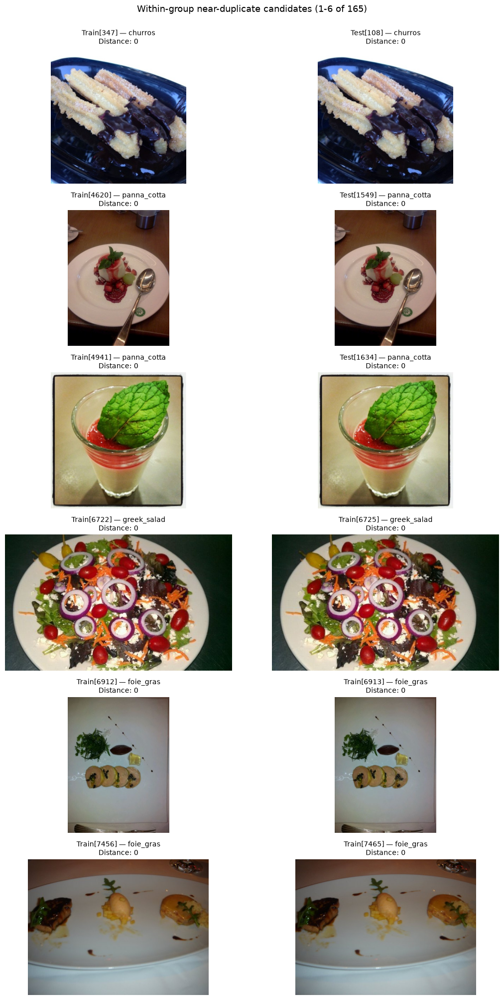

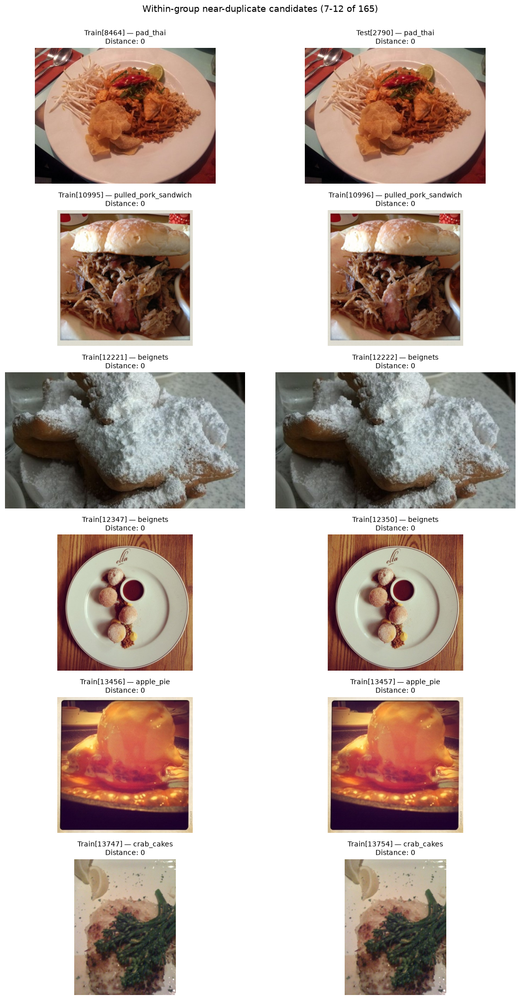

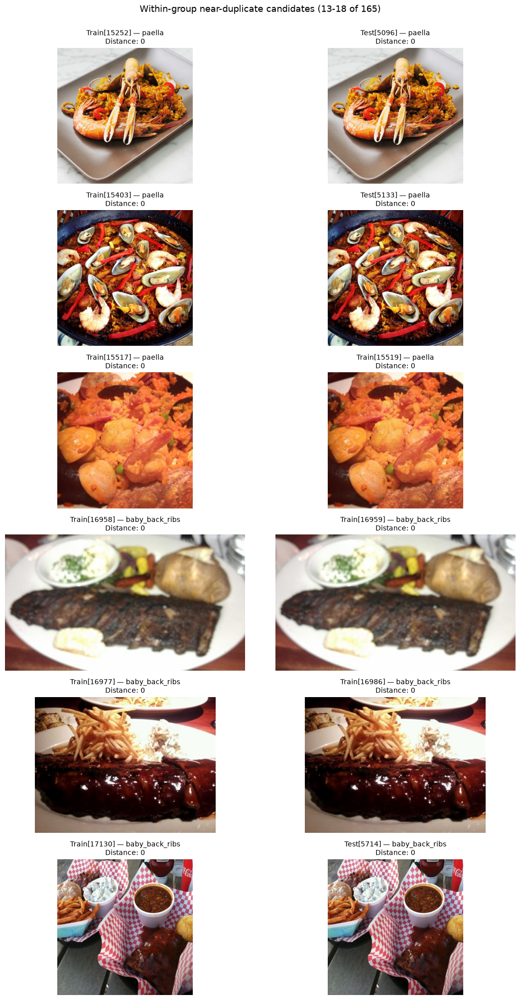

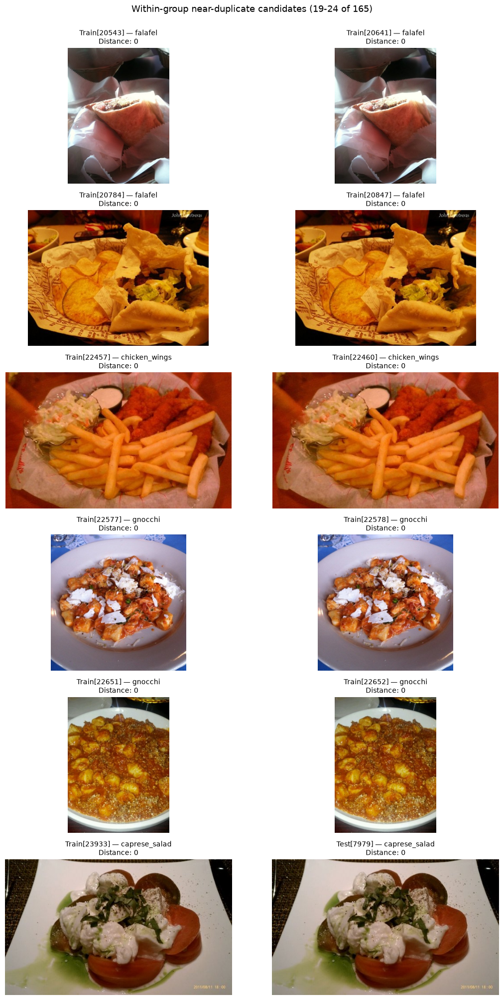

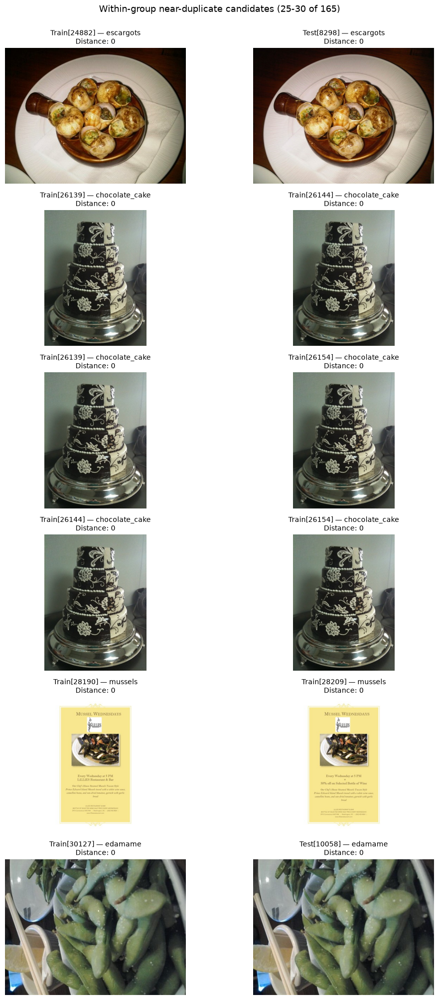

...

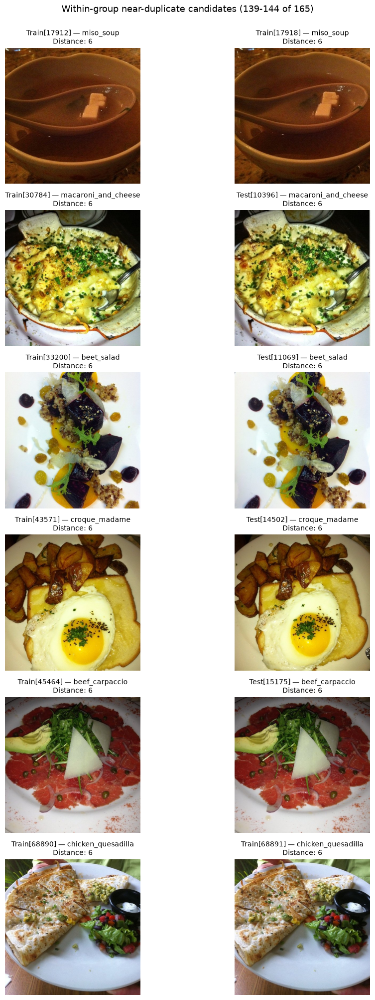

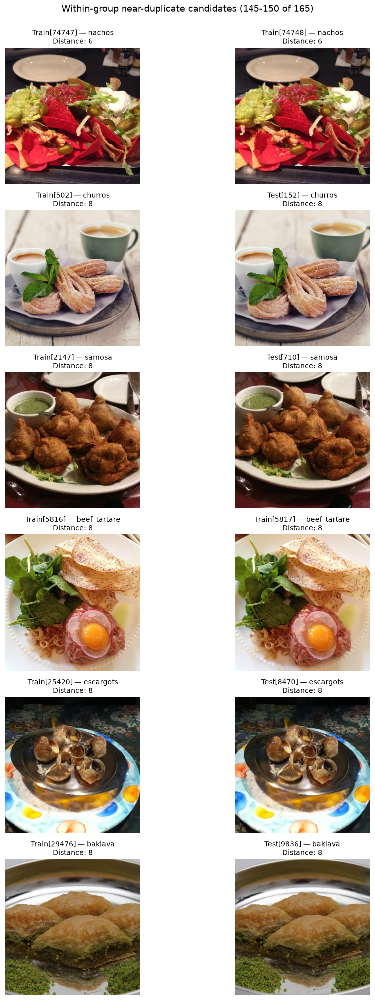

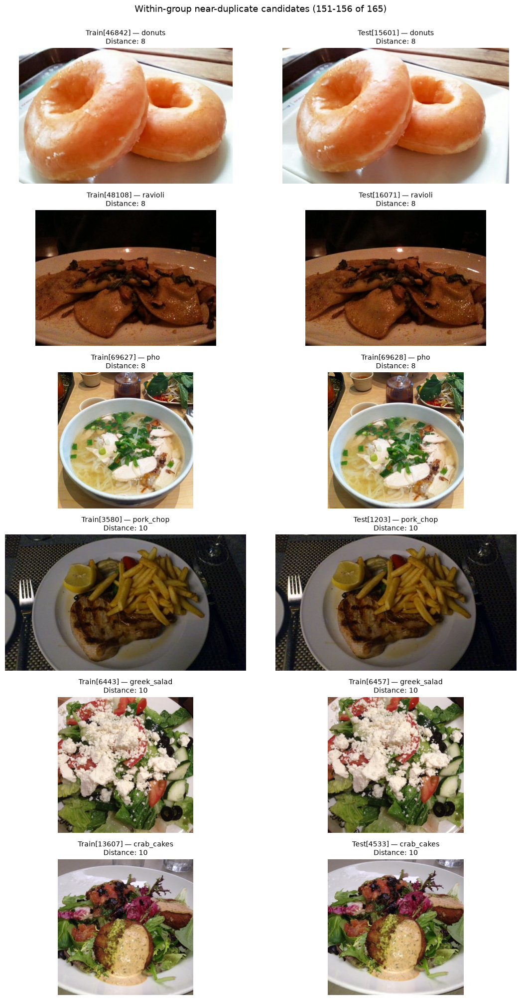

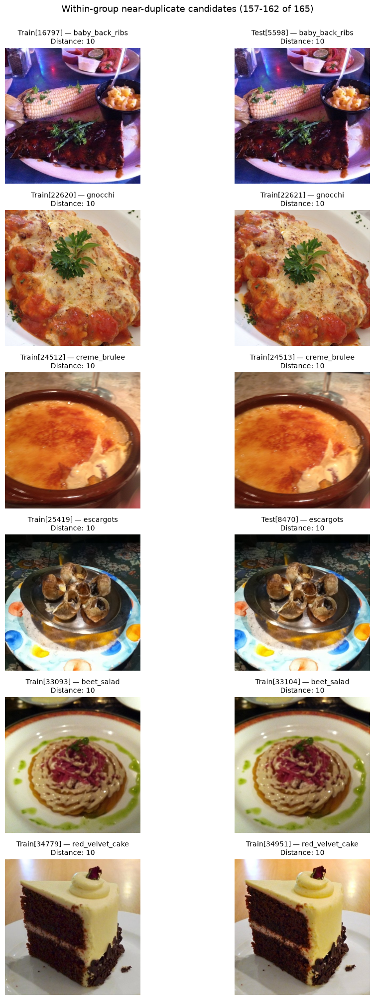

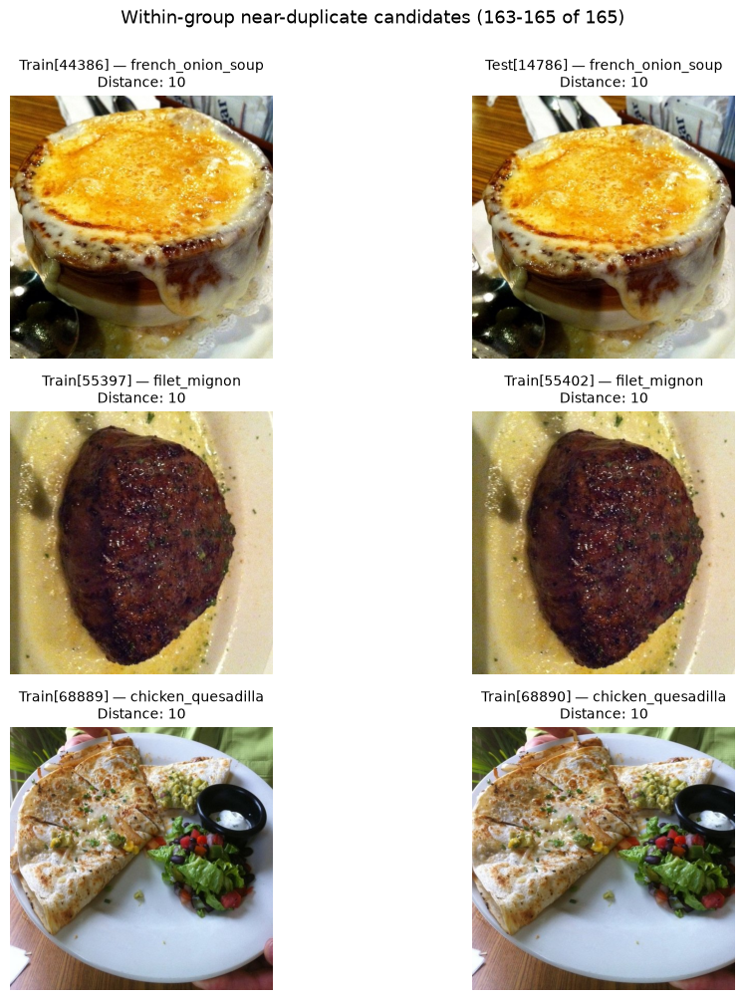

In [51]:
plot_duplicate_pairs(
    data_leakage_pairs,
    all_entries,
    full_train,
    full_test,
    pairs_per_figure=PAIRS_PER_FIGURE,
    max_pairs=PLOT_LIMIT,
)